# Run sets: consecutive runs as one timeline

Some runs continue one another (e.g. **r562 → r563 → r564**). Here each set is one timeline: train 8 of r562 is
followed by train 0 of r563, and so on. (`bubble_runs_analysis.ipynb` instead compares the same train number
across runs.)

A set is a results folder named `<name>_set` (from `bubble_inference.ipynb`), whose runs are taken from the frame
names inside it, or an explicit list of runs in `RUN_SETS`.

| section | question |
|---|---|
| 2 timeline | bubble count (and size, coverage, area, ...) through every train of every run of the set |
| 3 run boundaries | does the next run continue where the previous one ended, or is there a jump? |
| 4 runs within the set | does each run evolve the same way (relative to its own first train)? |
| 5 size distribution | the size distribution through the whole set |
| 6 trends | the trend over the whole set |
| **7 findings** | **text box to paste back to Claude** |

In [19]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2
import bubble_stats as bst
import bubble_compare as bc
import bubble_sets as bset

bst.style()
F = bc.Findings()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## CONFIG

In [20]:
RESULTS_ROOT = "results"
RUN_SETS = {"r560_set": bset.runs_in_folder("results/r560_set")}           # None = every `<name>_set` folder; or e.g. {"r562-r564": ["r562", "r563", "r564"]}
                               # (runs in time order; runs not in a _set folder are read from results/<run>/)
FRAME_IDX = 10                 # frame number used in every train
REVIEWED_ONLY = False
IN_ANALYSIS_ONLY = True
EXPORT_MISSING = True          # write bubbles.csv from the shape files where it is missing (needs the .tif copies)

# x axis: "seq" = trains in order, "slot" = leaves a gap for missing trains, "t_min" = real time (needs TRAIN_MINUTES)
X_AXIS = "seq"
TRAIN_MINUTES = None           # minutes between trains, e.g. 2.5 (or {run: minutes})
RUN_GAP_MINUTES = None         # extra minutes between the last train of a run and train 0 of the next (default: one
                               # train interval), or {run: minutes before that run}
RUN_TRAINS = None              # {run: number of trains} for "slot" when the last trains have no frame
UM_PER_PX = 3.2
SMALL_UM = 10.0
BOUNDARY_Z = 2.0               # |z| above which a run boundary counts as a jump
ALPHA = 0.05

OUT_DIR = os.path.join(RESULTS_ROOT, "_sets", f"frame{FRAME_IDX:03d}")
SAVE_FIGS = True

def save(fig, name):
    if SAVE_FIGS:
        os.makedirs(os.path.join(OUT_DIR, "figures"), exist_ok=True)
        fig.savefig(os.path.join(OUT_DIR, "figures", name + ".png"), dpi=200, bbox_inches="tight")

## 1. Load

In [21]:
SETS = RUN_SETS or bset.discover_sets(RESULTS_ROOT)
print("sets:", SETS)
bubbles, frames = bset.load_sets(SETS, RESULTS_ROOT, frame_idx=FRAME_IDX, reviewed_only=REVIEWED_ONLY,
                                 in_analysis_only=IN_ANALYSIS_ONLY, export_missing=EXPORT_MISSING)
frames = bset.timeline(frames, SETS, train_minutes=TRAIN_MINUTES, run_gap_minutes=RUN_GAP_MINUTES, run_trains=RUN_TRAINS)
m = bset.set_metrics(bubbles, frames, um_per_px=UM_PER_PX, small_um=SMALL_UM)
os.makedirs(OUT_DIR, exist_ok=True)
m.to_csv(os.path.join(OUT_DIR, "metrics.csv"), index=False)
display(m[["set", "seq", "run", "train", "n_bubbles", "r_mean_um", "r32_um", "coverage_frac", "area_total_um2",
           "frac_small"]].round(3))

for s, runs in SETS.items():
    g = m[m["set"] == s]
    if g.empty:
        F.add("Data", f"{s}: not loaded (see the messages above, e.g. not exported yet)")
        continue
    F.add("Data", f"{s}: runs {' → '.join(runs)}, frame {FRAME_IDX}, {len(g)} frames "
          f"({', '.join(f'{r} trains {int(x.train.min())}–{int(x.train.max())}' for r, x in g.groupby('run', sort=False))}), "
          f"{int(g['n_bubbles'].sum())} bubbles, {int(frames.loc[frames['set'] == s, 'reviewed'].sum())} frames reviewed")

sets: {'r560_set': ['r559', 'r560', 'r561']}
--- r560_set: runs r559, r560, r561 from results/r560_set, results/r560
WARNING results/r560: skipped 7 frame(s) already loaded from results/r560_set; set RUNS to choose which folder to use
3 runs, 28 frames, 2492 bubbles


,trains,n_frames,bubbles
run,,,
r559,"0,1,2,3,4,5,6,7,8,9,10,11,12",13,753
r560,"0,1,2,3,4,5,6",7,966
r561,"0,1,2,3,4,5,6,7",8,773


,set,seq,run,train,n_bubbles,r_mean_um,r32_um,coverage_frac,area_total_um2,frac_small
0,r560_set,0,r559,0,3,14.784,16.242,0.001,2172.466,0.000
1,r560_set,1,r559,1,3,12.510,15.590,0.001,1656.928,0.667
2,r560_set,2,r559,2,3,11.366,16.032,0.001,1512.622,0.333
3,r560_set,3,r559,3,4,11.894,14.959,0.001,2000.403,0.500
4,r560_set,4,r559,4,4,12.180,14.069,0.001,1999.269,0.250
5,r560_set,5,r559,5,4,11.995,14.120,0.001,1960.463,0.500
6,r560_set,6,r559,6,4,12.052,14.680,0.001,2023.600,0.250
7,r560_set,7,r559,7,4,11.305,15.272,0.001,1881.884,0.500
8,r560_set,8,r559,8,150,14.387,26.348,0.078,131147.277,0.340
9,r560_set,9,r559,9,137,14.716,27.693,0.076,127508.934,0.336


## 2. Timeline

Every train of every run in order; dashed lines mark where the next run starts. The top row is the bubble count,
written at each point.

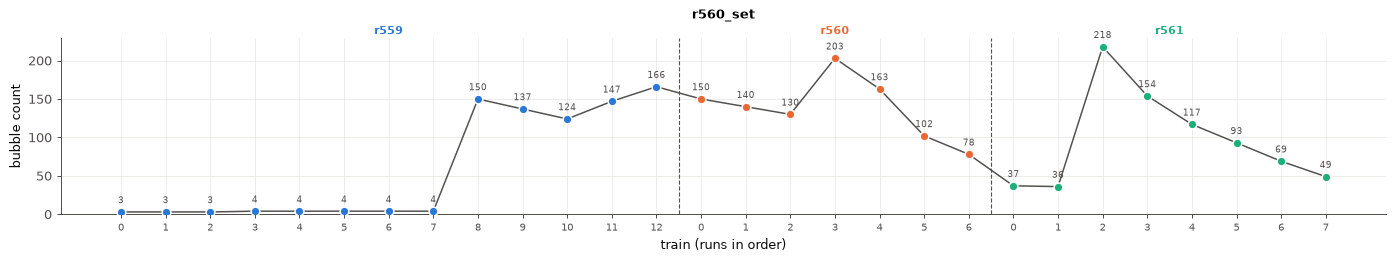

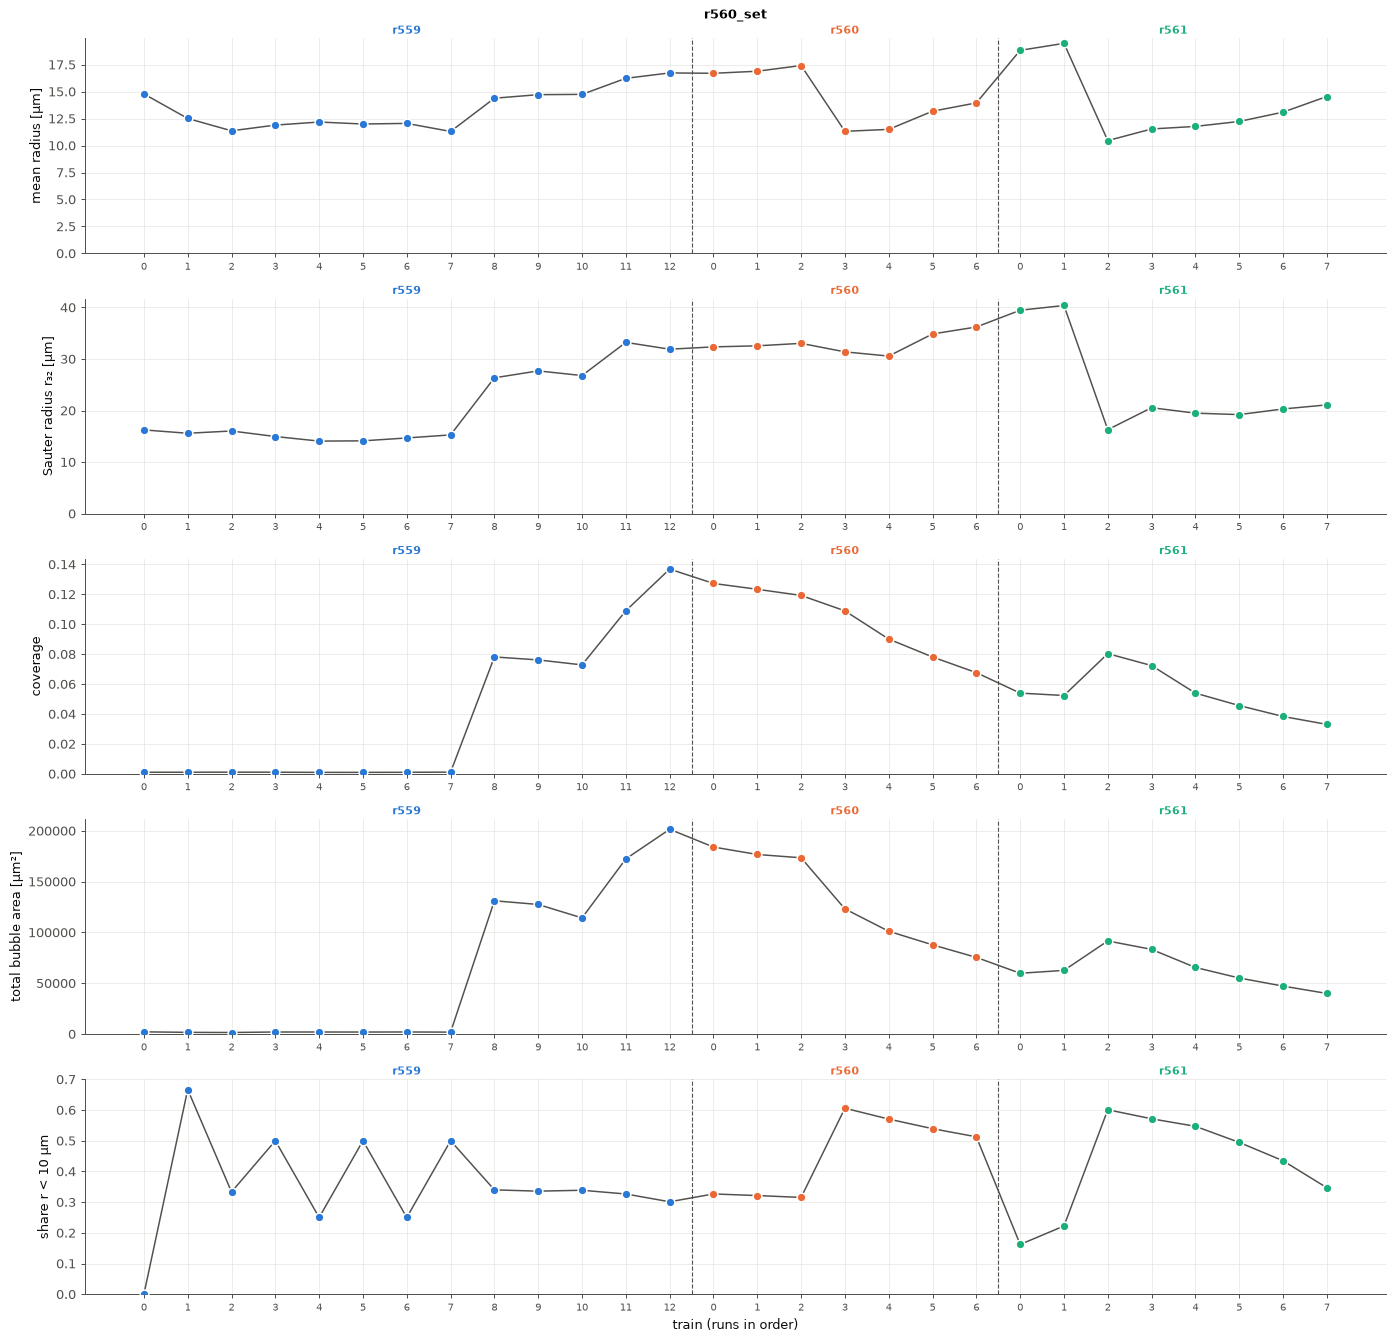

In [13]:
SPECS = [("n_bubbles", "bubble count"), 
         ("r_mean_um", "mean radius [µm]"), 
         ("r32_um", "Sauter radius r₃₂ [µm]"),
         ("coverage_frac", "coverage"), 
         ("area_total_um2", "total bubble area [µm²]"),
         ("frac_small", f"share r < {SMALL_UM:g} µm")
        ]
SPECS = [s for s in SPECS if s[0] in m]
fig = bset.plot_timelines(m, SPECS[:1], x=X_AXIS)
save(fig, "timeline_count")
fig = bset.plot_timelines(m, SPECS[1:], x=X_AXIS, annotate_first=False)
save(fig, "timeline_other")

F.clear("Timeline")
for s, g in m.sort_values("seq").groupby("set", sort=False):
    a, b = g.iloc[0], g.iloc[-1]
    i_max, i_min = g["n_bubbles"].idxmax(), g["n_bubbles"].idxmin()
    F.add("Timeline", f"{s}: count {a.n_bubbles:.0f} ({a.run} t{a.train}) → {b.n_bubbles:.0f} ({b.run} t{b.train}), "
          f"×{b.n_bubbles / max(a.n_bubbles, 1):.2f}; max {g.loc[i_max, 'n_bubbles']:.0f} at {g.loc[i_max, 'run']} "
          f"t{g.loc[i_max, 'train']}, min {g.loc[i_min, 'n_bubbles']:.0f} at {g.loc[i_min, 'run']} t{g.loc[i_min, 'train']}")
    F.add("Timeline", f"{s}: mean radius {a.r_mean_um:.1f} → {b.r_mean_um:.1f} µm (×{b.r_mean_um / a.r_mean_um:.2f}), "
          f"r32 {a.r32_um:.1f} → {b.r32_um:.1f} µm, coverage {a.coverage_frac:.2f} → {b.coverage_frac:.2f}, "
          f"total area ×{b.area_total_um2 / a.area_total_um2:.2f}")
    F.add("Timeline", f"{s} count by train: " + " | ".join(
        f"{run}: " + " ".join(f"{v:.0f}" for v in x["n_bubbles"]) for run, x in g.groupby("run", sort=False)))

## 3. Run boundaries

The change from the last train of a run to the first train of the next, compared with the steps between trains
inside the runs. `z` is how unusual the boundary step is (robust z-score of ln ratio): |z| below `BOUNDARY_Z` means
the next run simply continues; larger means a jump at the boundary (a pause between runs, the sample or field of
view moving, a new layer, ...).

In [14]:
bd = bset.boundaries(m)
bd.to_csv(os.path.join(OUT_DIR, "boundaries.csv"), index=False)
display(bd.round(3))
F.clear("Run boundaries")
for (s, fr, to), g in bd.groupby(["set", "from_run", "to_run"], sort=False):
    parts = []
    for r in g.itertuples():
        flag = " JUMP" if np.isfinite(r.z) and abs(r.z) > BOUNDARY_Z else ""
        parts.append(f"{r.metric} ×{r.ratio:.2f} (z {r.z:+.1f}{flag})")
    F.add("Run boundaries", f"{s} {fr} t{g.from_train.iloc[0]} → {to} t{g.to_train.iloc[0]}: " + ", ".join(parts))
if len(bd):
    typ = bd[bd["metric"] == "n_bubbles"]["typical_step"]
    F.add("Run boundaries", "typical count step inside runs: ×" + ", ".join(f"{v:.2f}" for v in typ.unique()) +
          " (median |change| per train)")

,set,metric,from_run,from_train,to_run,to_train,before,after,ratio,typical_step,z
0,r560_set,n_bubbles,r559,12,r560,0,166.000,150.000,0.904,1.185,-0.260
1,r560_set,n_bubbles,r560,6,r561,0,78.000,37.000,0.474,1.185,-2.523
2,r560_set,r_mean_um,r559,12,r560,0,16.731,16.697,0.998,1.046,-0.525
3,r560_set,r_mean_um,r560,6,r561,0,13.952,18.825,1.349,1.046,5.622
4,r560_set,r32_um,r559,12,r560,0,31.898,32.351,1.014,1.042,-0.009
5,r560_set,r32_um,r560,6,r561,0,36.208,39.459,1.090,1.042,1.175
6,r560_set,coverage_frac,r559,12,r560,0,0.137,0.127,0.930,1.110,-0.265
7,r560_set,coverage_frac,r560,6,r561,0,0.068,0.054,0.798,1.110,-1.309
8,r560_set,area_total_um2,r559,12,r560,0,201501.658,184026.250,0.913,1.164,-0.131
9,r560_set,area_total_um2,r560,6,r561,0,75444.033,59808.034,0.793,1.164,-1.151


## 4. Runs within the set

Each run against its own train number, divided by its first train. If the curves lie on top of each other, every
run does the same thing (e.g. the same response to a scan); if not, the state carried over from the previous run
matters.

,set,run,trains,n_frames,n_bubbles_first,n_bubbles_last,n_bubbles_mean,r_mean_um_first,r_mean_um_last,r_mean_um_mean,r32_um_first,r32_um_last,r32_um_mean,coverage_frac_first,coverage_frac_last,coverage_frac_mean
0,r560_set,r559,0–12,13,3,166,57.923,14.784,16.731,13.453,16.242,31.898,20.532,0.001,0.137,0.037
1,r560_set,r560,0–6,7,150,78,138.000,16.697,13.952,14.421,32.351,36.208,32.994,0.127,0.068,0.102
2,r560_set,r561,0–7,8,37,49,96.625,18.825,14.544,13.992,39.459,21.095,24.597,0.054,0.033,0.054


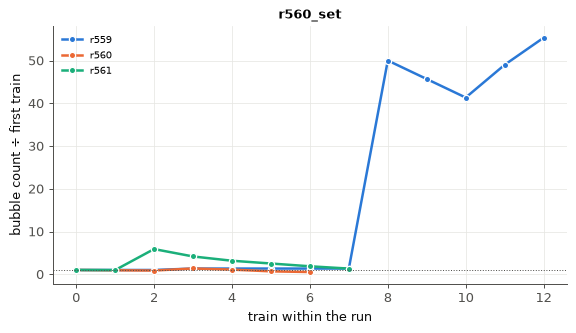

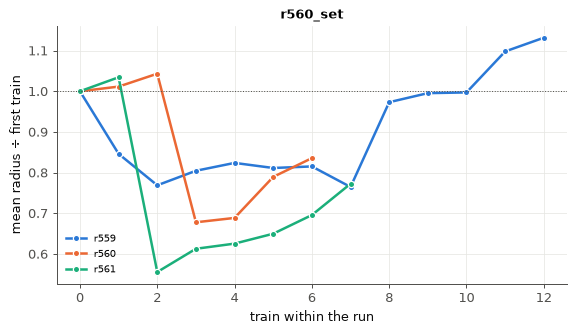

In [15]:
fig = bset.plot_relative_runs(m, "n_bubbles", "bubble count")
save(fig, "runs_relative_count")
fig = bset.plot_relative_runs(m, "r_mean_um", "mean radius")
save(fig, "runs_relative_radius")
rs = bset.run_summary(m)
display(rs.round(3))
F.clear("Runs within the set")
for r in rs.itertuples():
    F.add("Runs within the set", f"{r.set} {r.run} (trains {r.trains}): count {r.n_bubbles_first:.0f} → "
          f"{r.n_bubbles_last:.0f} (×{r.n_bubbles_last / max(r.n_bubbles_first, 1):.2f}, mean {r.n_bubbles_mean:.0f}), "
          f"mean r {r.r_mean_um_first:.1f} → {r.r_mean_um_last:.1f} µm")

## 5. Size distribution through the set

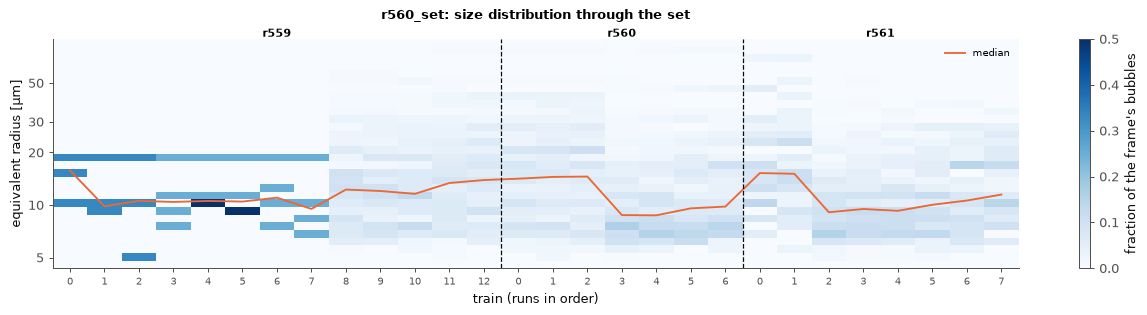

In [16]:
fig = bset.plot_size_timeline(bubbles, m)
save(fig, "size_timeline")

## 6. Trends over the whole set

Spearman ρ and a log-linear fit against the position in the set (`seq`, or `t_min` with real times): % change per
train over all runs together. Run boundaries with a jump (section 3) can dominate a trend, so read it with the
timeline plot.

In [17]:
xt = "t_min" if X_AXIS == "t_min" and "t_min" in m else "seq"
tr = pd.concat([bset.whole_set_trend(m, c, x=xt, log=c not in ("coverage_frac", "frac_small"))
                for c, _ in SPECS], ignore_index=True)
display(tr.round(4))
F.clear("Trends over the set")
unit = "minute" if xt == "t_min" else "train"
for r in tr.itertuples():
    sig = "significant" if r.p < ALPHA else "not significant"
    per = f"{r.pct_per_step:+.1f}% per {unit}" if np.isfinite(r.pct_per_step) else f"{r.slope:+.3g} per {unit}"
    F.add("Trends over the set", f"{r.set} {r.metric}: ρ = {r.rho:+.2f} ({bc.fmt_p(r.p)}, {sig}), {per}")

,set,metric,n,rho,p,slope,slope_p,pct_per_step
0,r560_set,n_bubbles,28,0.4699,0.0116,0.1357,0.0001,14.5313
1,r560_set,r_mean_um,28,0.0635,0.7482,0.0022,0.6039,0.2164
2,r560_set,r32_um,28,0.4729,0.0110,0.0183,0.0268,1.8462
3,r560_set,coverage_frac,28,0.3536,0.0649,0.0022,0.0333,NaN
4,r560_set,area_total_um2,28,0.3049,0.1147,0.1474,0.0002,15.8793
5,r560_set,frac_small,28,0.2465,0.2061,0.0049,0.1784,NaN


## 7. Findings

Copy the box into the chat. Also saved as `findings.txt` in `OUT_DIR`.

In [18]:
txt = F.text(f"RUN SETS TIMELINE, frame {FRAME_IDX} | sets {', '.join(SETS)} | x = {X_AXIS} | "
             f"{'reviewed only' if REVIEWED_ONLY else 'incl. unreviewed predictions'}")
with open(os.path.join(OUT_DIR, "findings.txt"), "w") as f:
    f.write(txt)
print(txt)

| RUN SETS TIMELINE, frame 10 | sets r560_set | x = seq | incl. unreviewed predictions                        |
|                                                                                                             |
| [Data]                                                                                                      |
| - r560_set: runs r559 → r560 → r561, frame 10, 28 frames (r559 trains 0–12, r560 trains 0–6, r561 trains    |
|   0–7), 2492 bubbles, 0 frames reviewed                                                                     |
|                                                                                                             |
| [Timeline]                                                                                                  |
| - r560_set: count 3 (r559 t0) → 49 (r561 t7), ×16.33; max 218 at r561 t2, min 3 at r559 t0                  |
| - r560_set: mean radius 14.8 → 14.5 µm (×0.98), r32 16.2 → 21.1 µm, coverage 0.00 → 0.03, total area ×

## Your analysis